In [1]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

for filename in uploaded:
    with zipfile.ZipFile(filename, "r") as z:
        z.extractall("/content")

os.chdir("/content/lab10")

!pip install -q "torch>=2.4,<3" "transformers==4.48.3" "datasets==3.2.0" "matplotlib>=3.7,<4" "pandas>=2,<3"

Saving lab10.zip to lab10.zip
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from qa_model import main, parser, ROOT
import pandas as pd
import torch
from IPython.display import display, Image, Markdown

args = parser().parse_args([])
{"device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU", "configuration": vars(args)}

{'device': 'Tesla T4',
 'configuration': {'model': 'distilbert-base-uncased',
  'train_size': 8000,
  'val_size': 1000,
  'test_size': 1500,
  'stride': 32,
  'batch_size': 8,
  'lr': 3e-05,
  'epochs': 3,
  'seed': 42,
  'output': '/content/lab10'}}

## Huấn luyện và đánh giá

In [3]:
results = main(args)
pd.DataFrame(results)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

,experiment,model,group,n,EM,F1,status,training_time_s,test_loss
0,model_comparison,keyword_overlap,Baseline,1500,5.533333,23.508765,measured,NaN,NaN
1,context_length,distilbert-base-uncased,128,1500,61.333333,72.132034,measured,693.611422,1.558087
2,context_length,distilbert-base-uncased,256,1500,62.333333,72.853629,measured,686.898555,1.789912
3,context_length,distilbert-base-uncased,384,1500,62.133333,73.726424,measured,959.330426,1.859477
4,model_comparison,distilbert-base-uncased,Fine-tuned,1500,62.133333,73.726424,measured,NaN,NaN
5,lexical_overlap,distilbert-base-uncased,high,999,67.067067,78.010986,measured,NaN,NaN
6,lexical_overlap,distilbert-base-uncased,low,501,52.295409,65.182957,measured,NaN,NaN
7,answer_length,distilbert-base-uncased,1,293,64.846416,72.811924,measured,NaN,NaN
8,answer_length,distilbert-base-uncased,2–3,561,68.627451,77.545813,measured,NaN,NaN
9,answer_length,distilbert-base-uncased,4–6,418,62.440191,73.841690,measured,NaN,NaN


## Context length

In [4]:
df = pd.read_csv(ROOT / "results.csv")
df[df.experiment == "context_length"][["group", "EM", "F1", "training_time_s"]]

,group,EM,F1,training_time_s
1,128,61.333333,72.132034,693.611422
2,256,62.333333,72.853629,686.898555
3,384,62.133333,73.726424,959.330426


## Learning curves

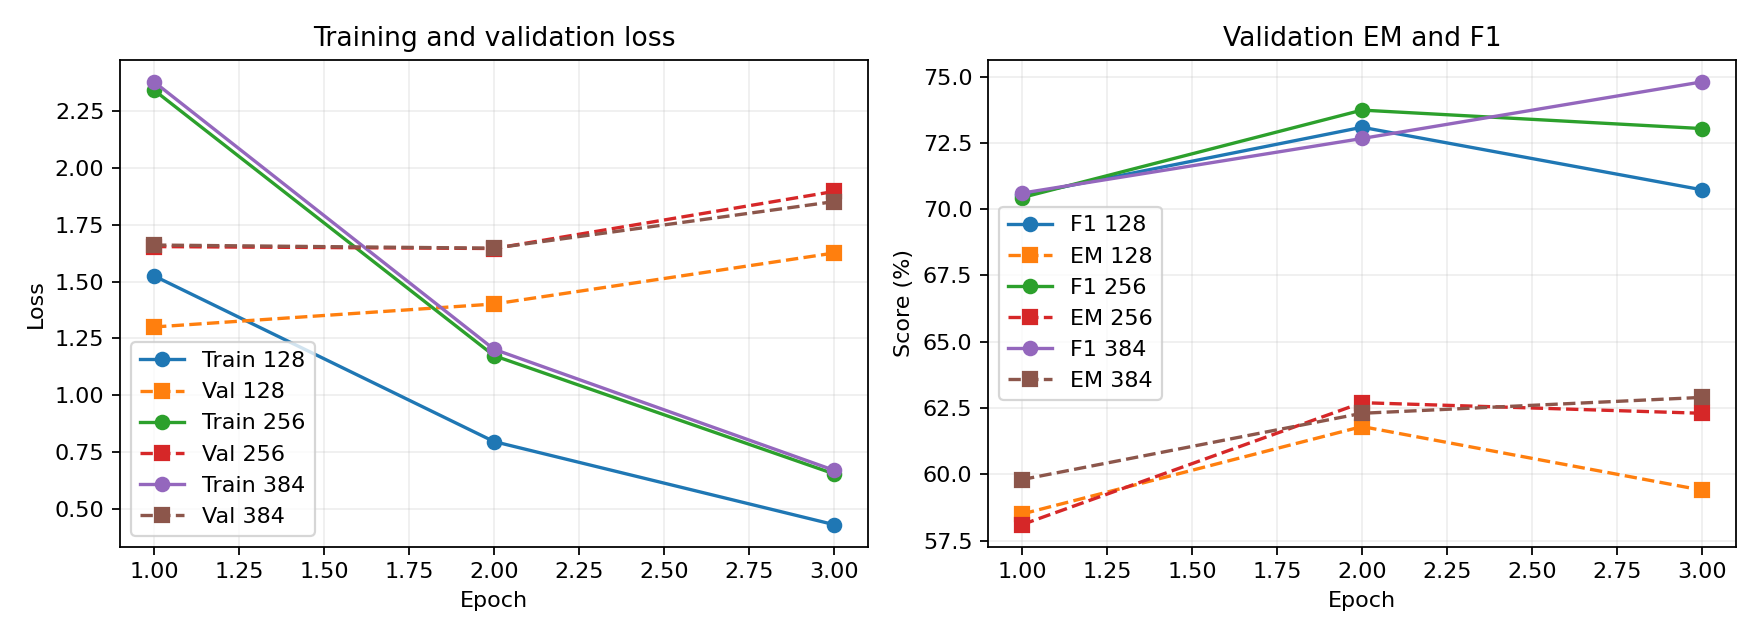

In [5]:
display(Image(filename=str(ROOT / "learning_curves.png")))

## Baseline và fine-tuned Transformer

,group,EM,F1
0,Baseline,5.533333,23.508765
4,Fine-tuned,62.133333,73.726424


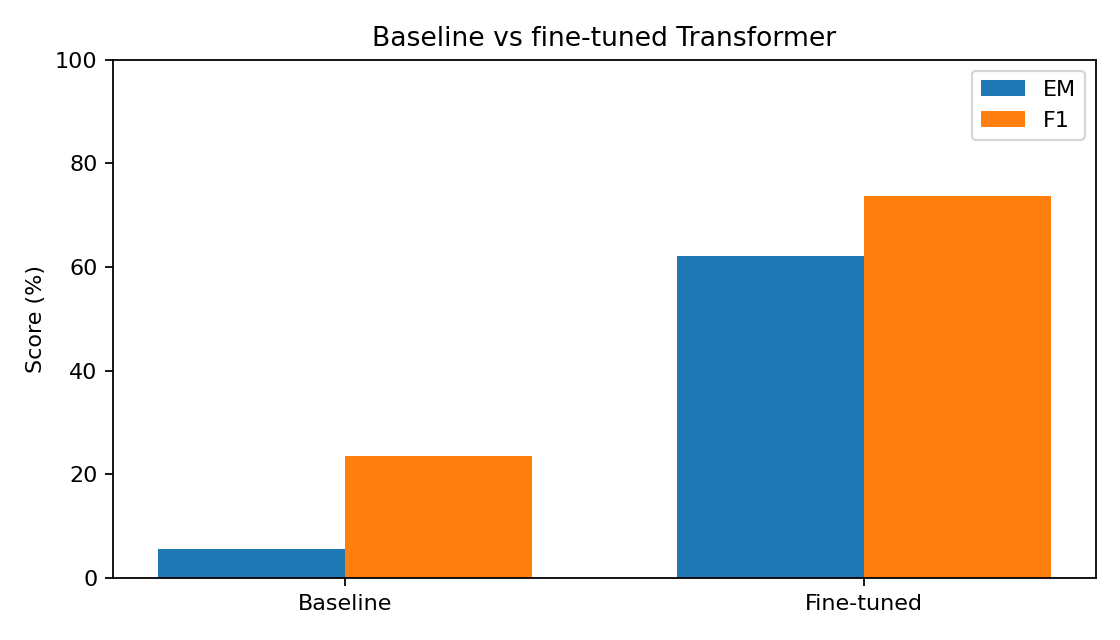

In [6]:
display(df[df.experiment == "model_comparison"][["group", "EM", "F1"]])
display(Image(filename=str(ROOT / "em_f1_analysis.png")))

## Question/context matching

In [7]:
df[df.experiment == "lexical_overlap"][["group", "n", "EM", "F1"]]

,group,n,EM,F1
5,high,999,67.067067,78.010986
6,low,501,52.295409,65.182957


## Answer length

,group,n,EM,F1
7,1,293,64.846416,72.811924
8,2–3,561,68.627451,77.545813
9,4–6,418,62.440191,73.841690
10,7+,228,42.105263,65.292609


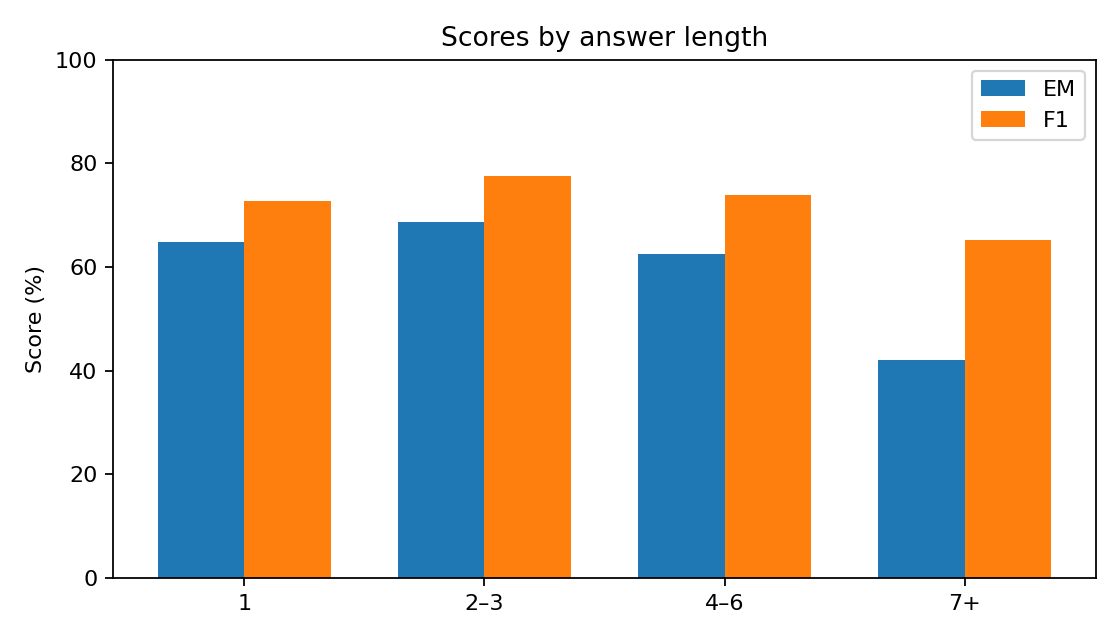

In [8]:
display(df[df.experiment == "answer_length"][["group", "n", "EM", "F1"]])
display(Image(filename=str(ROOT / "answer_length_analysis.png")))

## Irrelevant context, distractor và sentence order

In [9]:
df[df.experiment.isin(["irrelevant", "distractor", "reorder"])][["experiment", "group", "n", "EM", "F1"]]

,experiment,group,n,EM,F1
11,irrelevant,original,1500,62.133333,73.726424
12,irrelevant,modified,1500,62.466667,73.888233
13,distractor,original,1500,62.133333,73.726424
14,distractor,modified,1500,47.333333,55.401177
15,reorder,original,1440,62.222222,73.895190
16,reorder,modified,1440,60.902778,72.138650


## Error analysis

In [10]:
display(Markdown((ROOT / "error_analysis.md").read_text(encoding="utf-8")))

# Error analysis

Tổng số câu: 1500

Wrong start riêng: 185
Wrong end riêng: 123
Wrong span: 333
Tổng số sai start: 518
Tổng số sai end: 456

Các nhóm được xác định theo vị trí ký tự, đối chiếu với đáp án chuẩn có biên phù hợp nhất. EM và F1 lấy giá trị cao nhất trên các đáp án chuẩn.

## wrong start

Số ví dụ tìm được: 185

| Question | Gold | Prediction | Error type | Explanation | F1 |
|---|---|---|---|---|---:|
| What is the definition of agency as it relates to capabilities?  | the ability to pursue valued goals | ability to pursue valued goals | wrong start | Thiếu phần đầu của gold. Partial answer. | 1.0000 |
| What protection caused Luther's Reformation to flourish? | wing of the secular powers | under the wing of the secular powers | wrong start | Lấy thêm văn bản trước gold. | 0.8889 |
| Who was appointed as second in command to Lor Loudoun in 1756? | Major General James Abercrombie | James Abercrombie | wrong start | Thiếu phần đầu của gold. Partial answer. | 0.6667 |
| The mountain ranges tail off into what kind of geographical formation? | interior valleys | Transverse and Peninsular Ranges with their peaks, into the large and small interior valleys | wrong start | Lấy thêm văn bản trước gold. | 0.2667 |
| How do ctenophores control buoyancy? | It is uncertain | uncertain | wrong start | Thiếu phần đầu của gold. Partial answer. | 0.5000 |

## wrong end

Số ví dụ tìm được: 123

| Question | Gold | Prediction | Error type | Explanation | F1 |
|---|---|---|---|---|---:|
| Many organizations have recently called for broader acceptance of which community? | LGBT community | LGBT community within the UMC | wrong end | Lấy thêm văn bản sau gold. | 0.6667 |
| Whose theory did Tesla disagree with? | Einstein's | Einstein's theory of relativity | wrong end | Lấy thêm văn bản sau gold. | 0.4000 |
| What councils assign tasks to the IPCC? | WMO Executive Council and UNEP Governing Council | WMO Executive Council | wrong end | Thiếu phần cuối của gold. Partial answer. | 0.6000 |
| What is the oxygen partial pressure of space suits? | about 30 kPa (1.4 times normal) | about 30 kPa (1.4 times normal | wrong end | Thiếu phần cuối của gold. Partial answer. | 1.0000 |
| What is William Rankine's nationality? | Scottish | Scottish polymath | wrong end | Lấy thêm văn bản sau gold. | 0.6667 |

## wrong span

Số ví dụ tìm được: 333

| Question | Gold | Prediction | Error type | Explanation | F1 |
|---|---|---|---|---|---:|
| Who won the battle of Lake George? | inconclusively, with both sides withdrawing from the field | Fort Edward and Fort William Henry | wrong span | Span dự đoán nằm ngoài vị trí đáp án được chọn. | 0.0000 |
| What were the origins of the Raouliii family? | an Italo-Norman named Raoul | Italo-Norman | wrong span | Cả hai biên sai nhưng span còn giao với đáp án. Partial answer. | 0.5000 |
| Why did the 5th president of the university decide to get rid of the football program? | to emphasize academics over athletics | Robert Maynard Hutchins, took office; the university underwent many changes during his 24-year tenure. Hutchins eliminated varsity football | wrong span | Span dự đoán nằm ngoài vị trí đáp án được chọn. | 0.0000 |
| At what speed did the turbine operate? | 16,000 rpm | 100–5,000 hp | wrong span | Span dự đoán nằm ngoài vị trí đáp án được chọn. | 0.0000 |
| Classifying the stages of what is important to mapping aspects of the Amazon? | tree growth | classification of tree growth stages | wrong span | Cả hai biên sai nhưng span còn giao với đáp án. | 0.5714 |

## EM = 0 và F1 > 0

Số ví dụ tìm được: 333

| Question | Gold | Prediction | Error type | Explanation | F1 |
|---|---|---|---|---|---:|
| What were the origins of the Raouliii family? | an Italo-Norman named Raoul | Italo-Norman | wrong span | Cả hai biên sai nhưng span còn giao với đáp án. Partial answer. | 0.5000 |
| What protection caused Luther's Reformation to flourish? | wing of the secular powers | under the wing of the secular powers | wrong start | Lấy thêm văn bản trước gold. | 0.8889 |
| Who was appointed as second in command to Lor Loudoun in 1756? | Major General James Abercrombie | James Abercrombie | wrong start | Thiếu phần đầu của gold. Partial answer. | 0.6667 |
| The mountain ranges tail off into what kind of geographical formation? | interior valleys | Transverse and Peninsular Ranges with their peaks, into the large and small interior valleys | wrong start | Lấy thêm văn bản trước gold. | 0.2667 |
| Classifying the stages of what is important to mapping aspects of the Amazon? | tree growth | classification of tree growth stages | wrong span | Cả hai biên sai nhưng span còn giao với đáp án. | 0.5714 |

## Nhận xét

Sai start có thể do model chọn thiếu từ bổ nghĩa hoặc lấy thêm từ đứng trước thực thể. Sai end có thể do model chọn thiếu thành phần phía sau hoặc mở rộng sang cụm từ lân cận. Sai cả hai biên có thể liên quan đến distractor, nhiều span hợp lý hoặc sự mơ hồ của câu hỏi. Truncation, context dài, thiếu thông tin và tokenization cũng là các giả thuyết cần kiểm tra trực tiếp bằng context và offset mapping. Không thể xác định nguyên nhân ngữ nghĩa chỉ từ hai vị trí biên.

F1 vẫn dương nếu prediction và gold có token chung sau normalization, dù EM bằng 0.


## Đối chiếu prediction

In [11]:
display(Markdown((ROOT / "experiment_analysis.md").read_text(encoding="utf-8")))

# Experiment analysis

## Context length

256 so với 128: EM thay đổi +1.00 điểm phần trăm, F1 thay đổi +0.72 điểm phần trăm.
384 so với 256: EM thay đổi -0.20 điểm phần trăm, F1 thay đổi +0.87 điểm phần trăm.

Max length lớn hơn không bảo đảm chất lượng tăng vì thông tin bổ sung có thể không liên quan. Thời gian và điểm số được ghi trong results.csv.

## Baseline

Fine-tuned so với Baseline: EM thay đổi +56.60 điểm phần trăm, F1 thay đổi +50.22 điểm phần trăm.

## Prediction 1

high so với low: EM thay đổi +14.77 điểm phần trăm, F1 thay đổi +12.83 điểm phần trăm.
modified so với original: EM thay đổi -14.80 điểm phần trăm, F1 thay đổi -18.33 điểm phần trăm.

Lexical overlap là phân nhóm quan sát; thí nghiệm distractor kiểm tra tác động của việc thêm câu chứa question.

## Prediction 2

2–3 so với 1: EM thay đổi +3.78 điểm phần trăm, F1 thay đổi +4.73 điểm phần trăm.
4–6 so với 2–3: EM thay đổi -6.19 điểm phần trăm, F1 thay đổi -3.70 điểm phần trăm.
7+ so với 4–6: EM thay đổi -20.33 điểm phần trăm, F1 thay đổi -8.55 điểm phần trăm.

## Prediction 3

modified so với original: EM thay đổi +0.33 điểm phần trăm, F1 thay đổi +0.16 điểm phần trăm.
modified so với original: EM thay đổi -14.80 điểm phần trăm, F1 thay đổi -18.33 điểm phần trăm.

## Prediction 4

modified so với original: EM thay đổi -1.32 điểm phần trăm, F1 thay đổi -1.76 điểm phần trăm.

Các chênh lệch trên mô tả tập test đã chọn, không tự chứng minh quan hệ nhân quả cho các nhóm quan sát.


## Document QA

In [12]:
from document_qa import DocumentQA, DOCUMENT
qa = DocumentQA(ROOT / "checkpoint")
questions = ["When was the Transformer architecture introduced?", "What does extractive question answering predict?", "What articles is SQuAD based on?"]
pd.DataFrame([{"question": q, **qa.answer(q, DOCUMENT)} for q in questions])

,question,text,start,end
0,When was the Transformer architecture introduced?,2017,47,51
1,What does extractive question answering predict?,the start and end positions of an answer in a ...,133,186
2,What articles is SQuAD based on?,Wikipedia,251,260


## Reproducibility

In [13]:
import json
json.loads((ROOT / "reproducibility.json").read_text(encoding="utf-8"))

{'Model': 'distilbert-base-uncased',
 'Tokenizer': 'distilbert-base-uncased fast',
 'Dataset': 'SQuAD 1.1 rajpurkar/squad',
 'Train split': 8000,
 'Validation split': 1000,
 'Test split': 1500,
 'Max sequence length': [128, 256, 384],
 'Stride': 32,
 'Batch size': 8,
 'Learning rate': 3e-05,
 'Epochs': 3,
 'Optimizer': 'AdamW',
 'Random seed': 42,
 'Hardware': 'Tesla T4',
 'Training time': {'128': 693.611422387,
  '256': 686.898554744,
  '384': 959.330425635}}

In [14]:
%cd /content/lab10

!zip -q /content/lab10_results.zip *.md *.csv *.png *.json *.ipynb

from google.colab import files
files.download("/content/lab10_results.zip")

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>